In [11]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Set display styling
%matplotlib inline
plt.style.use('ggplot')

In [12]:
# Define root project directory and data paths
BASE_DIR = Path(".").resolve()
DATA_DIR = BASE_DIR / "data" / "raw"

MRI_DIR = DATA_DIR / "mri"
CT_DIR = DATA_DIR / "ct"

print(f"Checking data path: {DATA_DIR}")
print(f"Data directory exists: {DATA_DIR.exists()}")

Checking data path: C:\Users\Dell\msc_final_project_24164385\data\raw
Data directory exists: True


In [13]:
def inspect_dataset_directory(modal_dir, modality_name="Modality"):
    data_records = []
    
    if not modal_dir.exists():
        print(f"Directory not found: {modal_dir}")
        return pd.DataFrame()

    for class_folder in modal_dir.iterdir():
        if class_folder.is_dir():
            class_name = class_folder.name
            files = [f for f in class_folder.glob("*") if f.is_file()]
            extensions = set(f.suffix.lower() for f in files)
            
            data_records.append({
                "Modality": modality_name,
                "Class": class_name,
                "File Count": len(files),
                "File Extensions": ", ".join(extensions) if extensions else "None"
            })
            
    df = pd.DataFrame(data_records)
    return df

mri_df = inspect_dataset_directory(MRI_DIR, "MRI")
ct_df = inspect_dataset_directory(CT_DIR, "CT")

combined_df = pd.concat([mri_df, ct_df], ignore_index=True)
combined_df

,Modality,Class,File Count,File Extensions
0,MRI,Healthy,2000,".jpeg, .jpg"
1,MRI,Tumor,3000,".jpeg, .jpg"
2,CT,Healthy,2300,".png, .jpg"
3,CT,Tumor,2318,".png, .jpg"


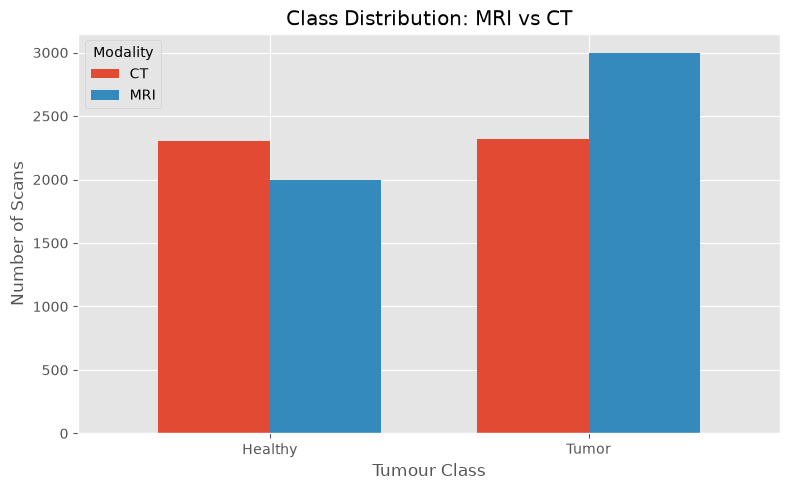

In [14]:
if not combined_df.empty:
    pivot_df = combined_df.pivot(index="Class", columns="Modality", values="File Count").fillna(0)
    
    ax = pivot_df.plot(kind="bar", figsize=(8, 5), width=0.7)
    plt.title("Class Distribution: MRI vs CT")
    plt.xlabel("Tumour Class")
    plt.ylabel("Number of Scans")
    plt.xticks(rotation=0)
    plt.legend(title="Modality")
    plt.tight_layout()
    plt.show()
else:
    print("Please populate data/raw/mri and data/raw/ct folders first.")

In [15]:
def inspect_image_properties(modal_dir, max_samples=50):
    image_paths = list(modal_dir.rglob("*.[pP][nN][gG]")) + list(modal_dir.rglob("*.[jJ][pP][gG]"))
    
    if not image_paths:
        print(f"No PNG/JPG images found in {modal_dir}")
        return
    
    shapes = []
    min_vals = []
    max_vals = []
    mean_vals = []
    
    for path in image_paths[:max_samples]:
        img = Image.open(path).convert("L")  # Convert to Grayscale
        arr = np.array(img)
        shapes.append(arr.shape)
        min_vals.append(arr.min())
        max_vals.append(arr.max())
        mean_vals.append(arr.mean())
        
    print(f"--- Properties for {modal_dir.name.upper()} (Sampled {len(shapes)} images) ---")
    print(f"Unique Shapes (H, W): {set(shapes)}")
    print(f"Pixel Intensity Range: Min = {min(min_vals)}, Max = {max(max_vals)}")
    print(f"Average Pixel Intensity: {np.mean(mean_vals):.2f}\n")

inspect_image_properties(MRI_DIR)
inspect_image_properties(CT_DIR)

--- Properties for MRI (Sampled 50 images) ---
Unique Shapes (H, W): {(400, 393), (444, 468), (630, 630), (640, 640), (224, 224), (251, 236), (256, 256)}
Pixel Intensity Range: Min = 0, Max = 255
Average Pixel Intensity: 67.56

--- Properties for CT (Sampled 50 images) ---
Unique Shapes (H, W): {(512, 512), (220, 229), (504, 427), (435, 327), (317, 239), (317, 229), (511, 352), (315, 230)}
Pixel Intensity Range: Min = 0, Max = 255
Average Pixel Intensity: 62.50

